# Clasificación de imágenes médicas con CNNs
## A - Objetivo

Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraidas de MRIs en una de 4 categorias. (Glioma, meningioma, pituitary y tejido sano)

## B - Conjunto de datos

Los datos corresponden a un dataset de 7023 imágenes extraídas de MRIs tomados
desde distintos ángulos y disponibles para dominio público. El dataset es accesible
en el siguiente enlace.

In [1]:
import os

for clase in sorted(os.listdir('archive')):
    ruta = os.path.join('archive', clase)
    if os.path.isdir(ruta):
        print(f"{clase}: {len(os.listdir(ruta))} imágenes")


glioma: 1621 imágenes
healthy: 2000 imágenes
meningioma: 1645 imágenes
pituitary: 1757 imágenes


## C - Actividades por realizar
1. Preparación de las imágenes para el entrenamiento y prueba del modelo.
Construya un pipeline para cargar las imágenes y dividirlas en conjuntos de
entrenamiento y prueba.
2. Desarrollo de la arquitectura de red neuronal convolucional para clasificación
de las imágenes de MRI en una de las 4 categorías. La arquitectura es de libre
elección, se recomienda utilizar bloques de convolución y max pooling o usar.

### 1. Librerias
Importación de librerias torch para crear los modelos de redes neuronales artificiales.

In [2]:
#Importamos las librerias requeridas
##Importamos pytorch von lod mofulod para construir redes neuronales

import torch
import torch.nn as nn
import torchvision
from torchvision.transforms import v2
from torch.utils.data import DataLoader, random_split
import torch.optim as optim      # Optimizadores de PyTorch

#Importamos pandas y numpy para trabajar los datos matriciales
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

#Inicializamos las semillas
torch.manual_seed(42)
np.random.seed(42)

#Se define el uso de GPU y cuda para el procesamiento de las redes convolucionales
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Preparación y preprocesamineto de imagenes

#### Variables globales

Definimos las variables gloables que usaremos durante todo el modelo.
1) El tamaño de 224 pixeles,usado, si bien no esta definido en la documentación de pytorch, según el bot de chatmigo, es una convención utilizada en modelos CNN. 
2) Para el tamaño del batch se tomo el valor de 32 ya que un batch mas pequeño puede ser mas lento, y un valor mas grande puede consumir mas recursos computacionales.

In [3]:
#Definición de las variables globales
category = ["glioma","healthy","meningioma","pituitary"]
img_size = (224,224)
batch_size = 32
seed = 42

#### Pipeline de transformación

Definimos el pipeline para la transformación de imagenes
1) Cambio de tamaño usando la variable global de img_size
2) Transformamos los datos en tensores para poder trabajar con ellos en las CNN´s
3) Aplicamos una normalización de los datos para estabilizar los datos de entrenamiento, convirtiendo los valores de los pixeles en un rango de 0 a 1

In [4]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.Resize(img_size),  # Ajusta a 224x224 píxeles
    transforms.ToTensor(),
    #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

#### Carga y división de los datos

1) Realizamos la carga de las imagenes en la variable dataset
2) Realizamos la división de los datos

In [ ]:
#Se realiza la carga de los datos, usando la función Image Folder
#Y nuestro previemente definido pipelin de tranformación.
dataset = torchvision.datasets.ImageFolder(root='archive', transform=transform)

#Se definen los tamaños de los conjuntos train,validaiton y test.
total_size = len(dataset)
train_size = int(0.8 * total_size)
val_size   = int(0.1 * total_size)
test_size  = total_size - train_size - val_size

#Se realiza la divsión de los datos.
trainset,valset,testset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(seed)
)

#### Función de visualización de instancias

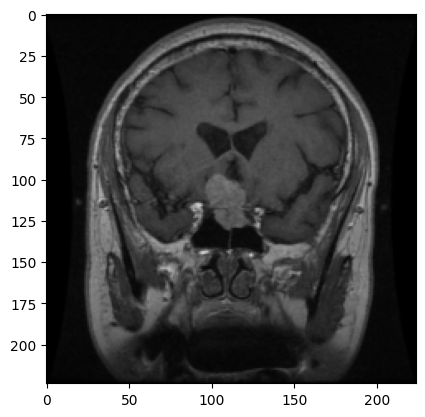

In [8]:
# functions to show an image
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainset)
images, labels = next(dataiter)
# show images
imshow(torchvision.utils.make_grid(images))
